# Lab 2: Developing Quantum Circuits in Python with Qiskit

Welcome back to our quantum lab series!  

In **Lab 1**, we learned to:
- Set up our quantum programming environment.
- Create single-qubit circuits.
- Apply basic Pauli gates.
- Simulate our circuits in multiple ways.

Now, in **Lab 2**, we’ll take those fundamentals and start building *more interesting* circuits.  

By the end of this lab, you will:
1. Create a **GHZ state** to explore multi-qubit entanglement.
2. Prepare the **|+⟩ state** and measure it in different bases.
3. Implement a **SWAP** operation using only CNOT (CX) gates.
4. Visualize results on both histograms and Bloch spheres.

We’ll continue using Qiskit and its AerSimulator so that we don’t depend on real quantum hardware (which has noise and queues).

## 1. Setup and Installation

We need to make sure Qiskit and related libraries are available.  
Run this cell **only if** you haven’t installed them yet.

In [1]:
%pip install qiskit qiskit-aer matplotlib

  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------  9.2/9.3 MB 47.7 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 38.4 MB/s  0:00:00
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.9 MB ? eta -:--:--
   ----------- ---------------------------- 2.9/9.9 MB 6.5 MB/s eta 0:00:02
   -------------- ------------------------- 3.7/9.9 MB 5.5 MB/s eta 0:00:02
   ------------------------- -------------- 6.3/9.9 MB 8.8 MB/s eta 0:00:01
   ---------------------------------- ----- 8.4/9.9 MB 8.4 MB/s eta 0:00:01
   ---------------------------------- ----- 8.4/9.9 MB 8.4 MB/s eta 0:00:01
   ---------------------------------- ----- 8.4/9.9 MB 8.4 MB/s eta 0:

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.59.1 requires cachetools<8,>=5.5, which is not installed.
streamlit 1.59.1 requires pandas<4,>=1.4.0, which is not installed.
streamlit 1.59.1 requires protobuf<8,>=3.20, which is not installed.
streamlit 1.59.1 requires pyarrow>=7.0, which is not installed.
tensorboard 2.15.2 requires protobuf!=4.24.0,>=3.19.6, which is not installed.
tensorflow-intel 2.15.0 requires ml-dtypes~=0.2.0, which is not installed.
tensorflow-intel 2.15.0 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<5.0.0dev,>=3.20.3, which is not installed.
tensorflow-intel 2.15.0 requires numpy<2.0.0,>=1.23.5, but you have numpy 2.4.6 which is incompatible.


## 2. Imports and Configuration

Here we import:
- Essential Qiskit classes for circuits and simulation.
- Visualization tools for histogram plots and Bloch spheres.
- `Statevector` for representing and inspecting quantum states exactly.
- A fixed random seed to make sure our results are reproducible (important for consistent demos).

In [1]:
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator, Aer
from qiskit.visualization import plot_histogram
import matplotlib
from math import pi, sqrt #pi = 3.14
from qiskit.visualization import plot_bloch_multivector
from qiskit.visualization import plot_histogram
from IPython.display import display
from qiskit.quantum_info import Statevector

## 3. A Reusable Run-and-Plot Function

Running a circuit is a bit repetitive:
1. **Transpile** — prepare code for the backend.
2. **Simulate** — execute and get results.
3. **Visualize** — show measurement counts.

We'll wrap this in a single helper function so we can focus on quantum thinking, not boilerplate.

In [2]:
SEED = 2024
sim = AerSimulator(seed_simulator=SEED)

def run_and_plot(qc, shots=1024, title=None):
    tqc = transpile(qc, sim)
    result = sim.run(tqc, shots=shots).result()
    counts = result.get_counts()
    fig = plot_histogram(counts, title=(title or qc.name or "Results"))
    display(fig)
    return counts

## 4. The GHZ State — Multi-Qubit Entanglement

The GHZ state for 3 qubits is:

|GHZ⟩ = (|000⟩ + |111⟩) / √2

**Why it’s special:**
- It’s maximally entangled: measuring one qubit immediately "collapses" the others.
- All qubits are *perfectly correlated* — they’re either all 0 or all 1.

**Circuit steps:**
1. Apply **H** to qubit 0 → creates 50/50 superposition.
2. Apply **CNOT** from qubit 0 → 1 → entangles them.
3. Apply **CNOT** from qubit 0 → 2 → entangles all three.
4. Measure all qubits.

**Prediction:** In the histogram, only `000` and `111` should appear (≈50% each).

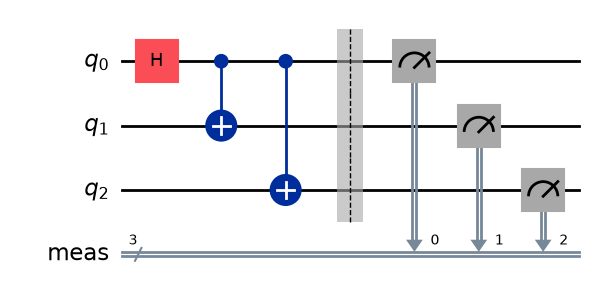

In [3]:
qc_ghz = QuantumCircuit(3, name="GHZ")
qc_ghz.h(0)
qc_ghz.cx(0, 1)
qc_ghz.cx(0, 2)
qc_ghz.measure_all()

display(qc_ghz.draw("mpl"))


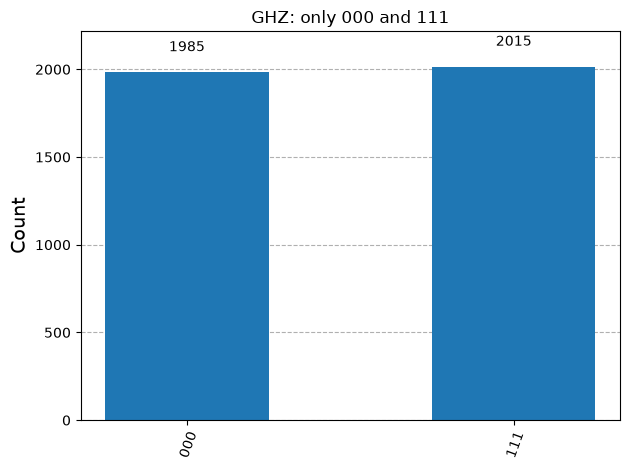

Counts: {'000': 1985, '111': 2015}


In [4]:
counts_ghz = run_and_plot(qc_ghz, shots=4000, title="GHZ: only 000 and 111")
print("Counts:", counts_ghz)

## 5. The |+⟩ State — Measurement Depends on Basis

The + state is:

|+⟩ = (|0⟩ + |1⟩) / √2

We get it by applying **H** to |0⟩.

**Two measurement strategies:**
1. **Z-basis (computational basis)**:
   - No basis change — measure as usual.
   - Expect roughly equal '0' and '1' outcomes.
2. **X-basis**:
   - Apply **H** before measuring to change the basis.
   - Expect always '0', since |+⟩ is the +1 eigenstate of X.

This illustrates a key quantum truth: *what you choose to measure changes what you see*.

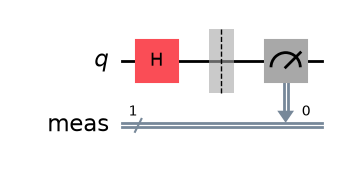

In [5]:
# Prepare the |+> state
qc_plus_state = QuantumCircuit(1, name="Prepare |+>")
qc_plus_state.h(0)

# Circuit 1: Measure |+> in the Z-basis (should be 50/50)
qc_measure_z = qc_plus_state.copy(name="Measure Z")
qc_measure_z.measure_all()
display(qc_measure_z.draw("mpl"))

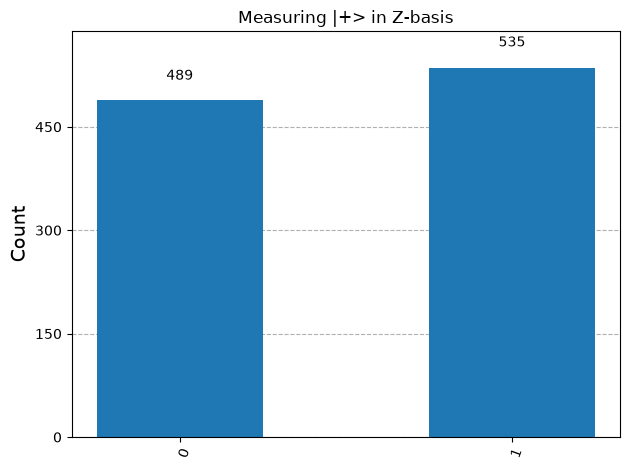

{'1': 535, '0': 489}

In [6]:
run_and_plot(qc_measure_z, title="Measuring |+> in Z-basis")

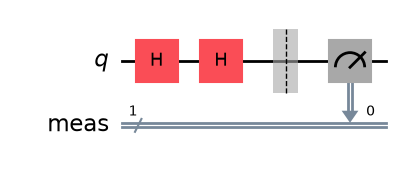

In [7]:
# Circuit 2: Measure |+> in the X-basis (should be 100% |+>, so we get "0")
qc_measure_x = qc_plus_state.copy(name="Measure X")
qc_measure_x.h(0) # Apply H to switch from X-basis to Z-basis
qc_measure_x.measure_all()
display(qc_measure_x.draw("mpl"))

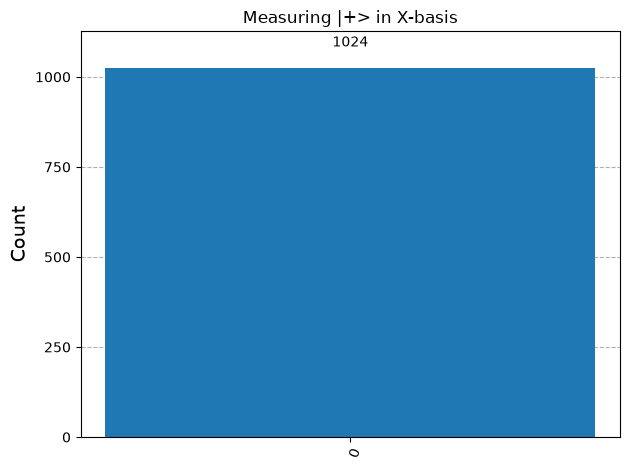

{'0': 1024}

In [8]:
run_and_plot(qc_measure_x, title="Measuring |+> in X-basis")

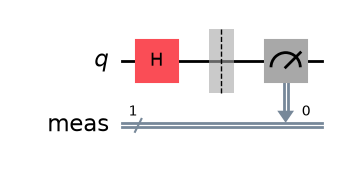

In [9]:
# Prepare the |+> State
qc_plus_state = QuantumCircuit(1, name="Prepare |+>")
qc_plus_state.h(0)

# Circuit 1: Measure |+> in the z-basis (should be 50/50)
qc_measure_z = qc_plus_state.copy(name="Measure Z")
qc_measure_z.measure_all()
display(qc_measure_z.draw("mpl"))

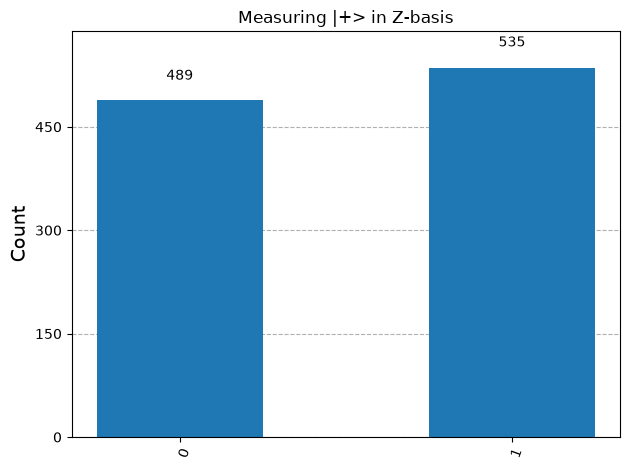

{'1': 535, '0': 489}

In [10]:
run_and_plot(qc_measure_z, title="Measuring |+> in Z-basis")

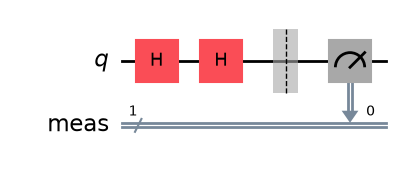

In [11]:
# Circuit 2: Measure |+> in the X-basis (should be 100% |+>, so we get "0")
qc_measure_x = qc_plus_state.copy(name="Measure X")
qc_measure_x.h(0)
qc_measure_x.measure_all()
display(qc_measure_x.draw("mpl"))

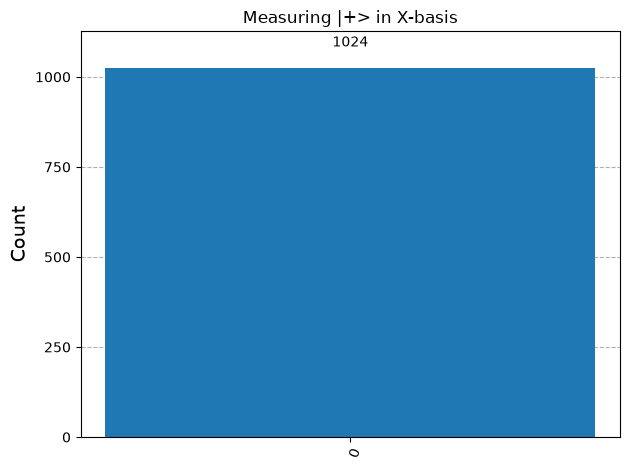

{'0': 1024}

In [12]:
run_and_plot(qc_measure_x, title="Measuring |+> in X-basis")

## 6. SWAP Gate from CNOTs — Gate Decomposition

The SWAP gate swaps the states of two qubits.

It can be "built" from three CNOTs:
SWAP(q0,q1) = CX(q0→q1) → CX(q1→q0) → CX(q0→q1)

Why this matters:
- Real quantum computers have a limited gate set.
- Complex gates (like SWAP) are decomposed into basic gates.

Here, we:
1. Prepare an arbitrary state on qubit 0.
2. SWAP it to qubit 1.
3. Inspect the statevector and Bloch spheres to confirm.

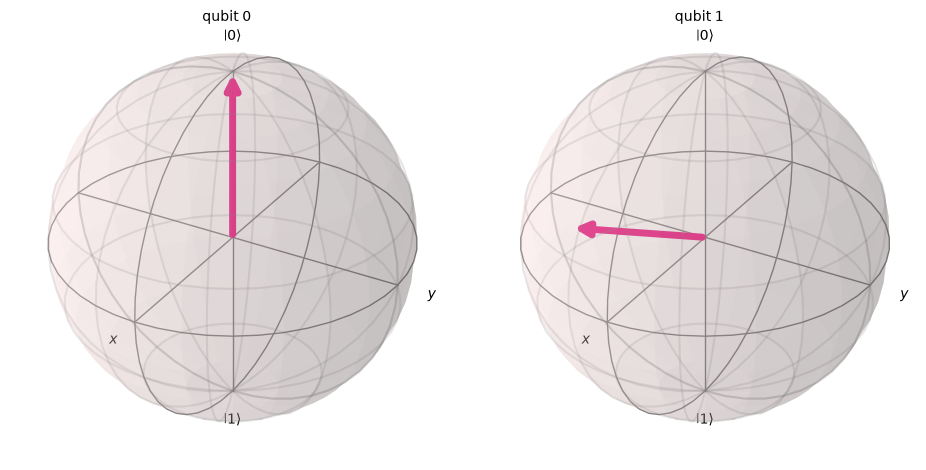

Statevector: Statevector([0.8236391 -0.1545085j , 0.        +0.j        ,
             0.47552826-0.26761657j, 0.        +0.j        ],
            dims=(2, 2))


In [13]:
# Build SWAP using three CX gates
qc_swap_nom = QuantumCircuit(2, name="SWAP via 3 CNOTs (no measure)")
qc_swap_nom.ry(pi/3, 0)
qc_swap_nom.rx(pi/5, 0)
qc_swap_nom.cx(0, 1)
qc_swap_nom.cx(1, 0)
qc_swap_nom.cx(0, 1)

state_swap = Statevector.from_instruction(qc_swap_nom)
display(plot_bloch_multivector(state_swap))
print("Statevector:", state_swap)

## 7. SWAP with Measurement

Let’s now add measurement and confirm, via histogram, that the state truly moved to qubit 1.

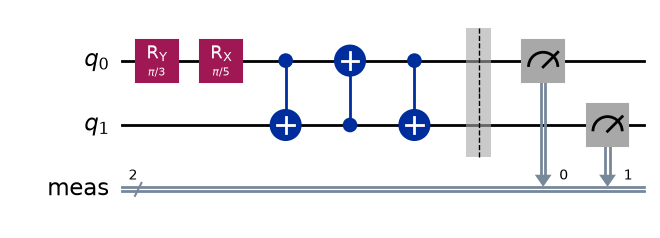

In [14]:
qc_swap = qc_swap_nom.copy()
qc_swap.measure_all()
display(qc_swap.draw("mpl"))

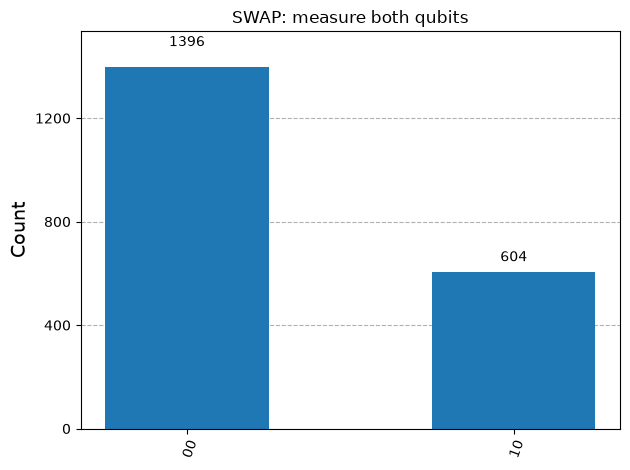

Counts: {'00': 1396, '10': 604}


In [15]:
counts_swap = run_and_plot(qc_swap, shots=2000, title="SWAP: measure both qubits")
print("Counts:", counts_swap)

## 8. The Bell States: The Four Flavors of Entanglement

We've seen 3-qubit entanglement with the GHZ state. Now, let's explore the simplest, most fundamental examples of entanglement: the four **Bell states**.

These four two-qubit states are maximally entangled and form a complete basis (the "Bell basis"). They are also known as **EPR pairs** (after Einstein, Podolsky, and Rosen) and are the workhorses for algorithms like quantum teleportation and superdense coding.

The four states are:
1.  **|Φ⁺⟩** = (`|00⟩` + `|11⟩`) / √2  *(Correlated)*
2.  **|Φ⁻⟩** = (`|00⟩` - `|11⟩`) / √2  *(Correlated, with a phase flip)*
3.  **|Ψ⁺⟩** = (`|01⟩` + `|10⟩`) / √2  *(Anti-correlated)*
4.  **|Ψ⁻⟩** = (`|01⟩` - `|10⟩`) / √2  *(Anti-correlated, with a phase flip)*

Let's build a circuit for each one.

### 8.1 |Φ⁺⟩: The "Standard" Entangled State

This is the most common Bell state you'll see. It's the two-qubit version of the GHZ state.

**How it works:**
1.  Apply a Hadamard (`H`) to qubit 0 to create superposition.
2.  Apply a CNOT (`CX`) with qubit 0 as control and qubit 1 as target.

**Expected Result:** The qubits are perfectly correlated. Measurement will yield `00` or `11` with equal probability.

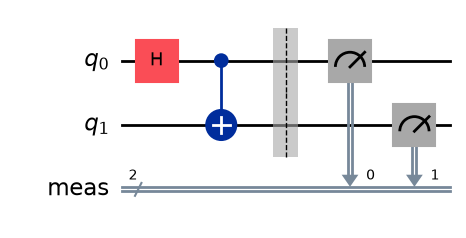

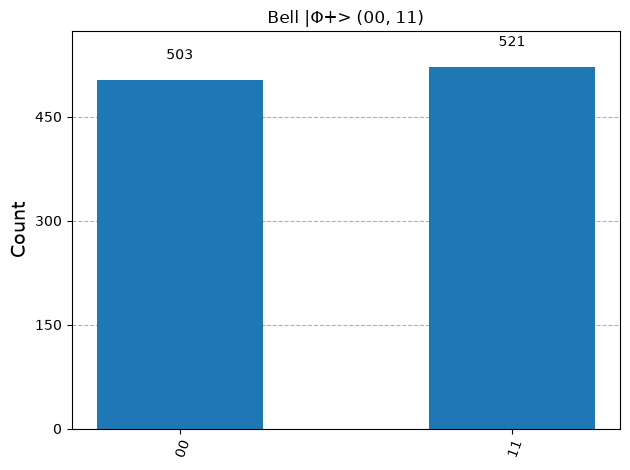

{'00': 503, '11': 521}

In [16]:
qc_phi_p = QuantumCircuit(2, name="Φ+")
qc_phi_p.h(0)
qc_phi_p.cx(0, 1)
qc_phi_p.measure_all()
display(qc_phi_p.draw("mpl"))
run_and_plot(qc_phi_p, title="Bell |Φ+> (00, 11)")

### 8.2 |Φ⁻⟩: Introducing a Phase Flip

The only difference between |Φ⁺⟩ and |Φ⁻⟩ is the minus sign, which represents a **relative phase difference**.

**How it works:**
To introduce this phase, we start the control qubit in the `|->` state instead of `|+>`. We do this by applying an `X` gate *before* the `H` gate on qubit 0.

**Expected Result:** Although the quantum state is different, measurement in the Z-basis is "blind" to this overall phase. The outcomes are identical to |Φ⁺⟩: you'll still only see `00` or `11`.

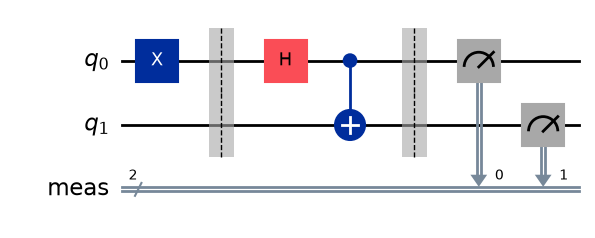

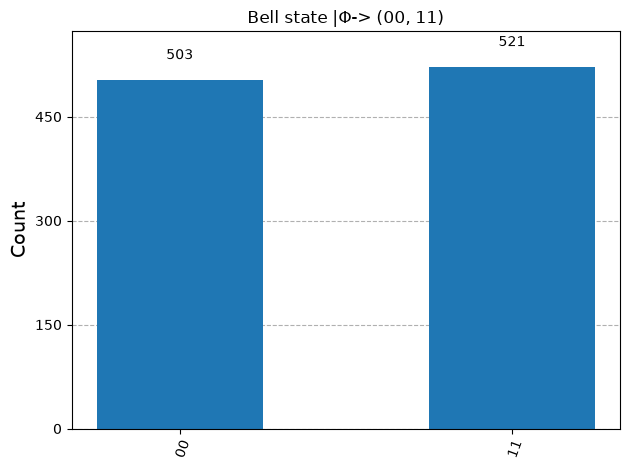

{'00': 503, '11': 521}

In [17]:
# 2. |Φ->
qc_phi_m = QuantumCircuit(2, name="Φ-")
qc_phi_m.x(0)
qc_phi_m.barrier()
qc_phi_m.h(0)
qc_phi_m.cx(0, 1)
qc_phi_m.measure_all()
display(qc_phi_m.draw("mpl"))
run_and_plot(qc_phi_m, title="Bell state |Φ-> (00, 11)")

### 8.3 |Ψ⁺⟩: The Anti-Correlated State

In this state, the qubits are **anti-correlated**. If you measure one as `0`, the other is guaranteed to be `1`, and vice versa.

**How it works:**
Instead of starting with the target qubit as `|0>`, we flip it to `|1>` using an `X` gate *before* the CNOT operation.

**Expected Result:** Measurement will yield `01` or `10` with equal probability.

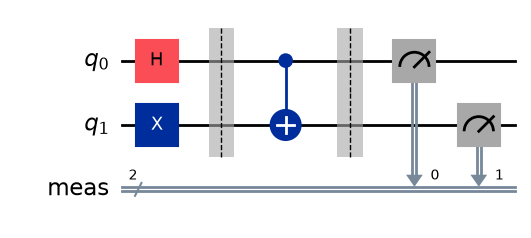

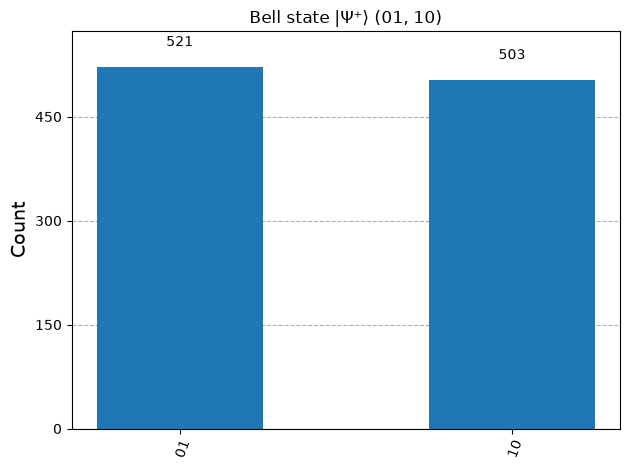

{'10': 503, '01': 521}

In [18]:
# 3. |Ψ⁺⟩
qc_psi_p = QuantumCircuit(2, name="Ψ+")
qc_psi_p.h(0)
qc_psi_p.x(1)
qc_psi_p.barrier()
qc_psi_p.cx(0,1)
qc_psi_p.measure_all()
display(qc_psi_p.draw("mpl"))
run_and_plot(qc_psi_p, title="Bell state |Ψ⁺⟩ (01, 10)")

### 8.4 |Ψ⁻⟩: The Singlet State

This state is famous in quantum mechanics and is often called the **singlet state**. It is both anti-correlated and has a relative phase flip.

**How it works:**
We combine the tricks from the previous states:
1.  Start the control qubit in the `|->` state (using `X` then `H`).
2.  Start the target qubit in the `|1>` state (using `X`).
3.  Apply the CNOT.

**Expected Result:** Like |Ψ⁺⟩, the measurements are anti-correlated, yielding only `01` or `10`.

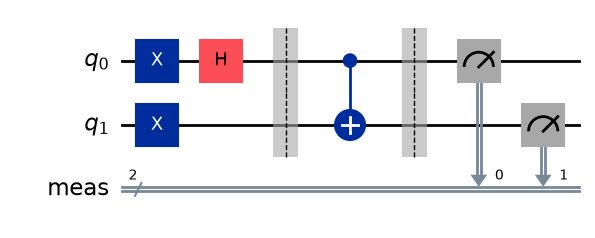

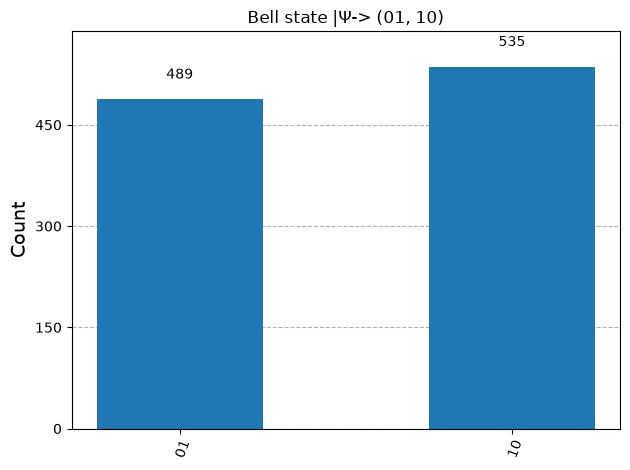

{'10': 535, '01': 489}

In [19]:
# 4. |Ψ-> (THe Singlet State)
qc_psi_m = QuantumCircuit(2, name="Ψ-")
qc_psi_m.x(0)
qc_psi_m.h(0)
qc_psi_m.x(1)
qc_psi_m.barrier()
qc_psi_m.cx(0, 1)
qc_psi_m.measure_all()
display(qc_psi_m.draw("mpl"))
run_and_plot(qc_psi_m, title="Bell state |Ψ-> (01, 10)")